# Preprocessing i odczyt danych w PyTorch

Przygotowujemy pary obraz–maska do przyszłego treningu modelu segmentacyjnego.
Korzystamy z gotowych przekrojów TIFF, metadanych `data/metadata/pairs.csv`
i ustalonego podziału pacjentów `data/splits/splits.csv`.
Nie losujemy nowego podziału; test pozostaje do końcowej oceny.

Obraz przekształcamy z `(256, 256, 3)`, `uint8`, na `(3, 256, 256)`, `float32`,
z wartościami w `[0, 1]`. Maska zmienia się z `(256, 256)`, `0/255`,
na `(1, 256, 256)`, `float32`, `0/1`.
Dzielenie przez 255 jest stałym przekształceniem i nie wymaga statystyk zbioru.

Uruchamiaj komórki od góry, z kernelem **Python (inzynierka)**,
z katalogu projektu lub `notebooks/`. Notebook odczytuje pliki, ale nie zapisuje
przetworzonych obrazów ani nie zmienia metadanych.
Dodatkowe ćwiczenia oznaczono jako **DO ROZWAŻENIA USUNIĘCIA**; pozostają w pliku.

## 1. Biblioteki

`Path` obsługuje ścieżki, Pandas odczytuje i łączy tabele, a `tifffile` czyta TIFF.
NumPy służy do kontroli zgodności danych, Matplotlib do wykresów, a PyTorch do tensorów,
klasy `Dataset` i grupowania próbek przez `DataLoader`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
import torch
from torch.utils.data import Dataset, DataLoader

## 2. Ścieżki projektu

`Path.cwd()` wskazuje katalog roboczy kernela. Jeśli jest nim `notebooks/`,
przechodzimy do katalogu nadrzędnego. Ścieżki w CSV są względne wobec projektu;
pełną ścieżkę odtwarzamy przez `project_root / zapisana_sciezka`.

In [2]:
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

metadata_dir = project_root / "data" / "metadata"
split_dir = project_root / "data" / "splits"

## 3. Metadane i przydział przekrojów

Łączymy tabele po `patient_id`. `how="left"` zachowuje wszystkie pary,
a `validate="many_to_one"` sprawdza, czy jednemu pacjentowi odpowiada najwyżej jeden
wiersz przydziału. Następnie wybieramy trening, zachowując przekroje z oznaczeniem i z pustą maską.
Zgodność i kompletność podziału sprawdzono w notebooku 02.

In [3]:
pairs_df = pd.read_csv(metadata_dir / "pairs.csv")
splits_df = pd.read_csv(split_dir / "splits.csv")

pairs_with_split = pairs_df.merge(
    splits_df,
    on="patient_id",
    how="left",
    validate="many_to_one",
)

In [4]:
train_df = pairs_with_split[pairs_with_split["split"] == "train"]

## 4. Przykładowa para z oznaczeniem

Wybieramy pierwszy treningowy rekord z `has_annotation == True` i odczytujemy jego pliki.
Oczekujemy obrazu `(256, 256, 3)` i maski `(256, 256)`, oba typu `uint8`.
Nazwy plików pozwalają zidentyfikować sprawdzaną parę.

In [22]:
example_row = train_df[train_df["has_annotation"] == True].iloc[0]
image = tifffile.imread(project_root / example_row["image_path"])
mask = tifffile.imread(project_root / example_row["mask_path"])

print((image.shape, image.dtype, Path(example_row["image_path"]).name))
print((mask.shape, mask.dtype, Path(example_row["mask_path"]).name))

((256, 256, 3), dtype('uint8'), 'TCGA_CS_4941_19960909_11.tif')
((256, 256), dtype('uint8'), 'TCGA_CS_4941_19960909_11_mask.tif')


## 5. Konwersja jednej pary na tensory

`permute(2, 0, 1)` zmienia układ obrazu z `(H, W, C)` na `(C, H, W)`.
`.float()` ustawia `float32`, a dzielenie przez 255 skaluje intensywności do `[0, 1]`.
Nie wyrównuje to rozkładów intensywności pomiędzy pacjentami — jest to prosty wariant początkowy.

Warunek `mask > 0` zamienia oznaczenie na wartości logiczne, a `.float()` na `0.0/1.0`.
`unsqueeze(0)` dodaje pojedynczą oś kanału maski. Funkcja zwraca krotkę dwóch tensorów;
odczyt plików pozostaje poza nią.

In [6]:
def preprocess_pair(image, mask):
    image_tensor = torch.from_numpy(image).permute(2, 0, 1).float() / 255
    mask_tensor = torch.from_numpy(mask > 0).float().unsqueeze(0)

    return (image_tensor, mask_tensor)

Sprawdzamy kształty, typy i wartości po konwersji.
Oczekujemy obrazu `(3, 256, 256)` i maski `(1, 256, 256)`, oba `torch.float32`.
Maksimum obrazu może być mniejsze od 1; dla wybranej niepustej maski oczekujemy wartości `0` i `1`.

In [7]:
image_tensor, mask_tensor = preprocess_pair(image, mask)

print(image_tensor.shape, image_tensor.dtype, image_tensor.min(), image_tensor.max())
print(mask_tensor.shape, mask_tensor.dtype, mask_tensor.min(), mask_tensor.max(), torch.unique(mask_tensor))

torch.Size([3, 256, 256]) torch.float32 tensor(0.) tensor(0.9725)
torch.Size([1, 256, 256]) torch.float32 tensor(0.) tensor(1.) tensor([0., 1.])


Kontrola obejmuje brak `NaN` i nieskończoności, zgodność liczby pikseli oznaczenia
z `foreground_pixels` oraz zachowanie wartości obrazu.
`permute(1, 2, 0)` przywraca układ `(H, W, C)`, a `np.allclose` uwzględnia
niewielkie różnice obliczeń zmiennoprzecinkowych. Oczekujemy `True`, równych liczb i `True`.

In [8]:
print(torch.isfinite(image_tensor).all())
print(mask_tensor.sum().item(), example_row["foreground_pixels"])
print(np.allclose(image_tensor.permute(1, 2, 0).numpy() * 255, image))

tensor(True)
1426.0 1426
True


## 6. Przekrój z pustą maską

Sprawdzamy tę samą funkcję dla rekordu z `has_annotation == False`.
Kształty pozostają takie same, ale maska zawiera wyłącznie zero, a jej suma wynosi zero.
Pusta maska oznacza brak oznaczenia na przekroju, nie zdrowego pacjenta.
Oddzielne zmienne zachowują wcześniejszy przykład z oznaczeniem.

In [10]:
empty_row = train_df[train_df["has_annotation"] == False].iloc[0]
empty_image = tifffile.imread(project_root / empty_row["image_path"])
empty_mask = tifffile.imread(project_root / empty_row["mask_path"])

empty_image_tensor, empty_mask_tensor = preprocess_pair(empty_image, empty_mask)
print(empty_image_tensor.shape, empty_mask_tensor.shape)
print(empty_mask_tensor.unique(), empty_mask_tensor.sum())

torch.Size([3, 256, 256]) torch.Size([1, 256, 256])
tensor([0.]) tensor(0.)


## 7. Dataset — odczyt pojedynczych par na żądanie

`__init__` zapisuje tabelę i katalog projektu w obiekcie. `__len__` podaje liczbę przekrojów,
a `__getitem__` odczytuje wskazaną parę i stosuje `preprocess_pair`.
`dataset[index]` uruchamia `__getitem__(index)`.

Używamy `.iloc[index]`, czyli pozycji w tabeli, ponieważ po filtrowaniu etykiety indeksu mogą mieć luki.
`self.project_root` odwołuje się do ścieżki zapisanej w obiekcie.
Obrazy są odczytywane przy pobieraniu próbek; nie wczytujemy całego zbioru do pamięci.

In [11]:
class MRIDataset(Dataset):
    def __init__(self, pairs_df, project_root):
        self.pairs_df = pairs_df
        self.project_root = project_root

    def __len__(self):
        return self.pairs_df.shape[0]

    def __getitem__(self, index):
        row = self.pairs_df.iloc[index]
        image_path = self.project_root / row["image_path"]
        mask_path = self.project_root / row["mask_path"]
        return preprocess_pair(tifffile.imread(image_path), tifffile.imread(mask_path))

Tworzymy treningowy `Dataset`. Jego długość powinna wynosić 2714 — jest to liczba przekrojów,
a nie liczba pacjentów ani paczek.

In [12]:
train_dataset = MRIDataset(train_df, project_root)
print(len(train_dataset))

2714


## 8. DataLoader treningowy i pierwsza paczka

`DataLoader` pobiera pary z `Dataset` i łączy je w paczki po cztery próbki.
`shuffle=True` miesza kolejność przy kolejnych przejściach przez loader,
a `num_workers=0` pozostawia odczyt w procesie notebooka.
Na tym etapie nie ustalamy ziarna losowania paczek, więc wybrany przykład może się zmieniać;
przydział pacjentów w CSV pozostaje stały.

In [14]:
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
)

`next(iter(train_loader))` pobiera pierwszą paczkę z nowego iteratora.
Oczekujemy obrazów `(4, 3, 256, 256)` i masek `(4, 1, 256, 256)`.
Pierwszy wymiar to liczba próbek; obraz i odpowiadająca mu maska pozostają sparowane.

In [15]:
batch_images, batch_masks = next(iter(train_loader))

print(batch_images.shape)
print(batch_masks.shape)

torch.Size([4, 3, 256, 256])
torch.Size([4, 1, 256, 256])


Wyświetlamy pierwszą parę z paczki: `batch_images[0, 1]` wybiera przekrój `0` i kanał FLAIR `1`,
a `batch_masks[0, 0]` jego maskę. Wspólne `vmin=0, vmax=1` utrzymują stałą skalę wyświetlania.
Maska może być pusta, ponieważ trening zawiera również przekroje bez oznaczenia.

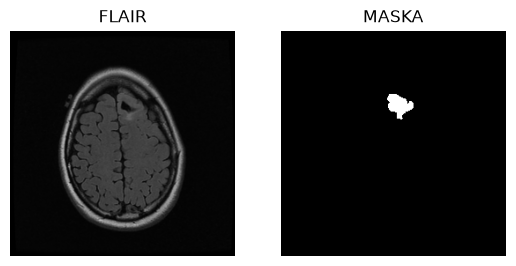

In [16]:
fig, axes = plt.subplots(1, 2)

axes[0].imshow(batch_images[0, 1], cmap="gray", vmin=0, vmax=1)
axes[0].set_title("FLAIR")
axes[0].axis("off")

axes[1].imshow(batch_masks[0, 0], cmap="gray", vmin=0, vmax=1)
axes[1].set_title("MASKA")
axes[1].axis("off")

plt.show()

## 9. Dataset i DataLoader walidacyjny

Wybieramy zapisany przydział `val` i stosujemy tę samą klasę oraz ten sam preprocessing.
`shuffle=False` zachowuje kolejność próbek. Oczekujemy 615 przekrojów,
a w pierwszej paczce takich samych kształtów jak dla treningu.

In [17]:
val_df = pairs_with_split[pairs_with_split["split"] == "val"]
val_dataset = MRIDataset(val_df, project_root)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print(len(val_dataset))

val_images, val_masks = next(iter(val_loader))
print(val_images.shape)
print(val_masks.shape)

615
torch.Size([4, 3, 256, 256])
torch.Size([4, 1, 256, 256])


## 10. Pełny odczyt walidacji i treningu

Pętle sprawdzają, czy można odczytać wszystkie próbki przez przygotowany preprocessing.
Sumujemy rzeczywistą liczbę próbek w każdej paczce przez `images.shape[0]`.
Po pętli `images` i `masks` przechowują ostatnią paczkę.

Domyślne `drop_last=False` zachowuje również niepełną ostatnią paczkę:
walidacja ma 615 próbek i ostatnią paczkę rozmiaru 3, a trening 2714 próbek i ostatnią paczkę rozmiaru 2.
Jest to kontrola odczytu danych; nie wykonujemy jeszcze treningu modelu.

In [18]:
n_samples = 0

for images, masks in val_loader:
    n_samples += images.shape[0]

print("Liczba odczytanych przekrojów:", n_samples)
print("Kształt ostatniej paczki obrazów:", images.shape)
print("Kształt ostatniej paczki masek:", masks.shape)

Liczba odczytanych przekrojów: 615
Kształt ostatniej paczki obrazów: torch.Size([3, 3, 256, 256])
Kształt ostatniej paczki masek: torch.Size([3, 1, 256, 256])


In [19]:
n_samples = 0

for images, masks in train_loader:
    n_samples += images.shape[0]

print("Liczba odczytanych przekrojów:", n_samples)
print("Kształt ostatniej paczki obrazów:", images.shape)
print("Kształt ostatniej paczki masek:", masks.shape)

Liczba odczytanych przekrojów: 2714
Kształt ostatniej paczki obrazów: torch.Size([2, 3, 256, 256])
Kształt ostatniej paczki masek: torch.Size([2, 1, 256, 256])
